In [1]:
import pandas as pd
import numpy as np

In [2]:
import matplotlib.pyplot as plt

In [5]:
df = pd.read_csv(r"C:\Users\Manya Ali\Desktop\manya ali 33142\student_tea_snacks _1_.csv")

In [6]:
df.head()

,student_id,gender,age_group,prefers_tea,tea_type,snack_choice,cups_per_day
0,S001,Male,21-23,No,Black,Samosa,2
1,S002,Male,21-23,No,Green,Samosa,3
2,S003,Male,18-20,No,Doodh Patti,Biscuit,0
3,S004,Male,21-23,Yes,NaN,Samosa,1
4,S005,Male,18-20,Yes,Green,Samosa,4


In [7]:
df.shape

(100, 7)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   student_id    100 non-null    str  
 1   gender        100 non-null    str  
 2   age_group     100 non-null    str  
 3   prefers_tea   100 non-null    str  
 4   tea_type      77 non-null     str  
 5   snack_choice  100 non-null    str  
 6   cups_per_day  100 non-null    int64
dtypes: int64(1), str(6)
memory usage: 8.3 KB


In [10]:
df.describe()

,cups_per_day
count,100.000000
mean,2.810000
std,1.673893
min,0.000000
25%,1.750000
50%,3.000000
75%,4.000000
max,5.000000


In [11]:
df.isnull().sum()

student_id       0
gender           0
age_group        0
prefers_tea      0
tea_type        23
snack_choice     0
cups_per_day     0
dtype: int64

In [12]:
# Q1: What is the most preferred tea type?

df.groupby("tea_type")["student_id"].count().sort_values(ascending=False)

tea_type
Green          29
Doodh Patti    25
Black          23
Name: student_id, dtype: int64

Green tea is the most preferred tea type with 29 students, followed by Doodh Patti (25) and Black (23).

In [13]:
# Q2: What is the average number of cups per gender?

df.groupby("gender")["cups_per_day"].mean()

gender
Female    2.595745
Male      3.000000
Name: cups_per_day, dtype: float64

Males drink an average of 3.00 cups per day, while females drink an average of 2.60 cups per day

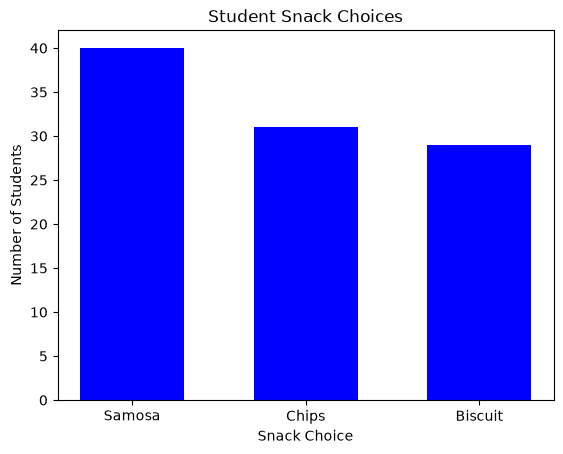

In [14]:
# Q3: Make a bar chart of snack choices.


snacks = df.groupby("snack_choice")["student_id"].count().sort_values(ascending=False)
plt.bar(snacks.index, snacks.values, color='blue', width=0.6)
plt.xlabel('Snack Choice')
plt.ylabel('Number of Students')
plt.title('Student Snack Choices')
plt.show()

In [15]:
# Q4: Compare tea preference by age group.

x = df.groupby(["age_group", "prefers_tea"])["student_id"].count()

y = df.groupby(["age_group", "tea_type"])["student_id"].count()

print(x)
print("")
print("")
print(y)

age_group  prefers_tea
18-20      No             19
           Yes            20
21-23      No             17
           Yes            15
24-26      No             13
           Yes            16
Name: student_id, dtype: int64


age_group  tea_type   
18-20      Black           9
           Doodh Patti    11
           Green          13
21-23      Black           9
           Doodh Patti     6
           Green           5
24-26      Black           5
           Doodh Patti     8
           Green          11
Name: student_id, dtype: int64


Across all age groups, tea preference is fairly balanced—in 18–20, 20 prefer tea (Yes) vs. 19 (No); in 21–23, 15 prefer tea (Yes) vs. 17 (No); and in 24–26, 16 prefer tea (Yes) vs. 13 (No).
By tea type, Green tea leads in 18–20 (13) and 24–26 (11), while Black tea leads in 21–23 (9)

In [16]:
# Q5: Count the number of students who don't drink tea.
len(df[df['cups_per_day'] == 0])

13

13 students drink 0 cups per day
